In [52]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import time

# Analysis of the results of the CSV'S resulting from the sim

In this notebook it will be shown the process of analyzing the resulting sim data and stablishing a pipeline which will lead to a .py projectwhich will automatically run after the GAMA sim and be able to extract the results via graphics and similar

First there is a lot of csvs. we need to joint them all into one

In [40]:
BASE_SIM_DIR = "20260310_182326"
#HARDCODDED NUMBER OF SIMS

N_SIMS = 1000

columns = ["simulation_id", "bus_code", "stop_num","timeslot","boards","residual_boards","dropoffs", "occupation", "time_between_stops"]

joint_dataframe_results = pd.DataFrame(columns=columns)

dataframes_to_join_results = []
for iteration in range(0,N_SIMS):
    new_dataframe = pd.read_csv(f"{os.getcwd()}/logs/SIMULATION_{BASE_SIM_DIR}/RESULTS/log_Simulation {iteration}.csv", encoding="utf-8")
    dataframes_to_join_results.append(new_dataframe)



joint_dataframe_results = pd.concat(data for data in dataframes_to_join_results)
joint_dataframe_results = joint_dataframe_results.rename(columns={"stops_listself.directionself.stops_reached.stopNum":"stop_num", "boards - residual_boards":"boards","self.passengers":"passengers"})

In [41]:
N_SIMS = 1000


columns = ["simulation_id", "bus_code", "stop_num", "timeslot", "event_code","time_event","param_event_1", "param_event_2"]

joint_dataframe_events = pd.DataFrame(columns=columns)

dataframes_to_join_events = []
for iteration in range(0,N_SIMS):
    new_dataframe = pd.read_csv(f"{os.getcwd()}/logs/SIMULATION_{BASE_SIM_DIR}/EVENTS/log_Simulation {iteration}.csv", encoding="utf-8")
    dataframes_to_join_events.append(new_dataframe)



joint_dataframe_events = pd.concat(data for data in dataframes_to_join_events)

Once joined the data, its time to start making the graphics results andif well done, elevate the process to a .py code that accepts the ISODATE of the sim as a parameter, and build a directory which holds the graphics results.

## Graphic 1. Statistics of simulation Occupation VS REAL TIME occupation

In [42]:
# la idea de esto es generar gráficas a mansalva. La idea detrás ed esto es poder tener tantas gráficas como se guste y en la interfaz de usuario poder agrupar esas gráficas para que se den varios puntos de vista.


#idea 1. A parte de hacer gráficas para todos los timeslots, agrupar por hardcodded timestamps (Mañana[5], Hora punta[6,9], Valle de Mañana[10,13], Hora tarde[14,19], noche[20,23]
timeslots = [5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23]



In [43]:
joint_dataframe_results

,world.name,self.id,stop_num,self.direction,current_time,TimeSlot,boards,residual_boards,dropoffs,passengers,self.time_travelled
0,Simulation 0,3579,2646,toA,5:25,5,0,0,0,0,0.0
1,Simulation 0,3579,562,toA,5:27,5,22,0,0,22,120.0
2,Simulation 0,3579,4090,toA,5:30,5,0,0,0,22,170.0
3,Simulation 0,3579,4188,toA,5:33,5,0,0,2,20,140.0
4,Simulation 0,3579,5939,toA,5:35,5,6,0,0,26,120.0
...,...,...,...,...,...,...,...,...,...,...,...
2695,Simulation 999,3561,5938,toB,23:45,23,0,0,0,0,230.0
2696,Simulation 999,3561,4187,toB,23:48,23,0,0,0,0,210.0
2697,Simulation 999,3561,2964,toB,23:51,23,0,0,0,0,130.0
2698,Simulation 999,3561,649,toB,23:52,23,0,0,0,0,60.0


# Estadísticas generales. Medidas de Rendimiento. % de ocupación medio, general, por franja horaria, Enfrentamiento real vs teórico "normal" de ocupacion

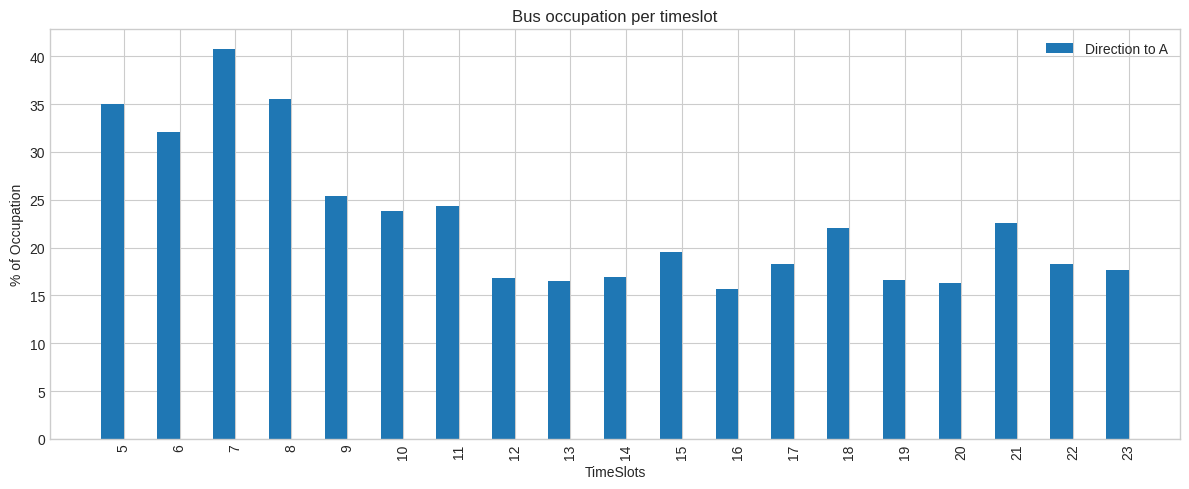

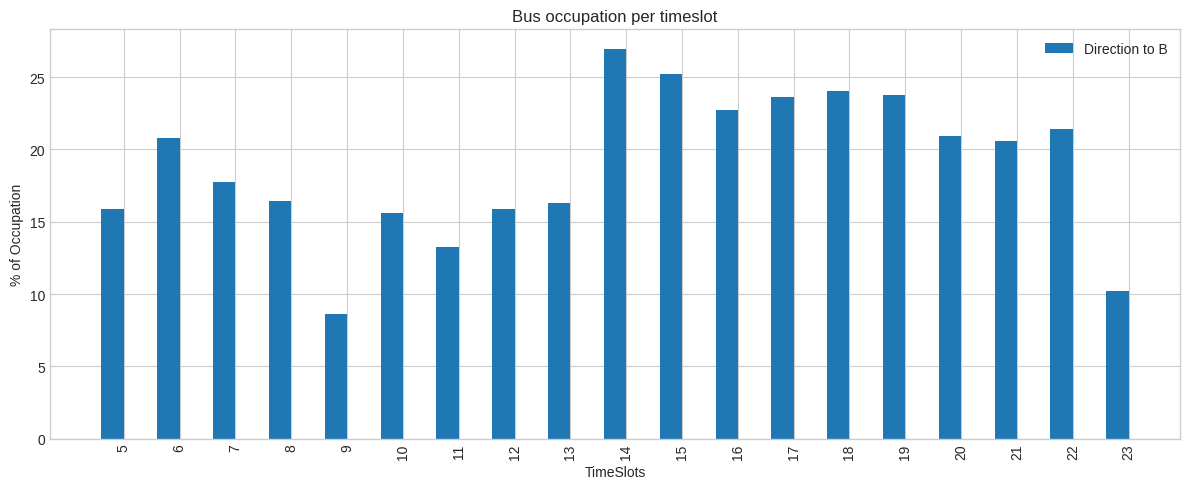

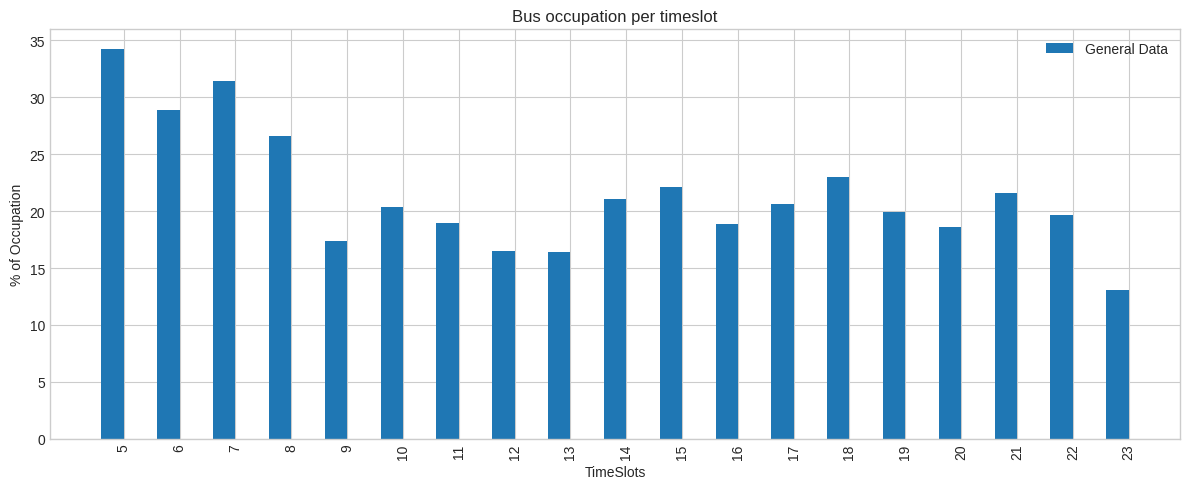

In [64]:
#KPI 1. % de ocupación medio. % de ocupacion por franja horaria. % de ocupación de cada autobús en acda una de sus franjas
MAX_CAPACITY = 80
#La easy.
percentage_occupation_per_stop = 0

#In toA

json_output_general_info = {}



data_toA = joint_dataframe_results[joint_dataframe_results["self.direction"] == "toA"]
data_toB = joint_dataframe_results[joint_dataframe_results["self.direction"] == "toB"]

json_output_general_info["Occupation_toA"] = (data_toA["passengers"].mean()/MAX_CAPACITY)*100
json_output_general_info["Occupation_toB"] = (data_toB["passengers"].mean()/MAX_CAPACITY)*100
json_output_general_info["Occupation"] = (joint_dataframe_results["passengers"].mean()/MAX_CAPACITY)*100



#Empiezan las graficassss
#graficas de evolucion a lo largo del tiempon de valor de %Occupation
list_occupation_values_toA = []
list_occupation_values_toB = []
list_occupation = []
for timeslot in timeslots:
    data_toA_per_ts = data_toA[data_toA["TimeSlot"] == timeslot]
    data_toB_per_ts = data_toB[data_toB["TimeSlot"] == timeslot]
    data_general = joint_dataframe_results[joint_dataframe_results["TimeSlot"] == timeslot]
    list_occupation_values_toA.append((data_toA_per_ts["passengers"].mean()/MAX_CAPACITY)*100)
    list_occupation_values_toB.append((data_toB_per_ts["passengers"].mean()/MAX_CAPACITY)*100)
    list_occupation.append((data_general["passengers"].mean()/MAX_CAPACITY)*100)


plt.style.use('seaborn-v0_8-whitegrid')

def save_barcode(horizontal_data, vertical_data, horizontal_label, vertical_label, leyend, label, filename):
    x = np.arange(len(horizontal_data))
    plt.figure(figsize=(12,5))
    plt.bar(x, vertical_data, width=0.4, label=leyend)
    plt.xticks(x + 0.2, horizontal_data, rotation=90)
    plt.ylabel(vertical_label)
    plt.xlabel(horizontal_label)
    plt.title(label)
    plt.legend()
    plt.tight_layout()
    plt.savefig(filename)

save_barcode(timeslots, list_occupation_values_toA , "TimeSlots", "% of Occupation",  "Direction to A", "Bus occupation per timeslot", f"{os.getcwd()}/logs/SIMULATION_{BASE_SIM_DIR}/PLOTS/occupation_per_timeslot_toA.png")

save_barcode(timeslots, list_occupation_values_toB , "TimeSlots", "% of Occupation",  "Direction to B", "Bus occupation per timeslot", f"{os.getcwd()}/logs/SIMULATION_{BASE_SIM_DIR}/PLOTS/occupation_per_timeslot_toB.png")

save_barcode(timeslots, list_occupation , "TimeSlots", "% of Occupation",  "General Data", "Bus occupation per timeslot",
             f"{os.getcwd()}/logs/SIMULATION_{BASE_SIM_DIR}/PLOTS/occupation_per_timeslot_general.png")